In [53]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
import os
from langchain_groq import ChatGroq
from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint
from langchain_core.prompts import PromptTemplate
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal, Annotated
from pydantic import BaseModel, Field
from langchain_core.messages import SystemMessage, HumanMessage, BaseMessage
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver



In [39]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
    

In [34]:
model = ChatGroq(
    model_name="openai/gpt-oss-20b",
    temperature=0
)


In [22]:
import requests
import os

api_key = os.environ.get("GROQ_API_KEY")
url = "https://api.groq.com/openai/v1/models"

headers = {
    "Authorization": f"Bearer {api_key}",
    "Content-Type": "application/json"
}

response = requests.get(url, headers=headers)

print(response.json())

{'object': 'list', 'data': [{'id': 'qwen/qwen3.8-27b', 'object': 'model', 'created': 1786984846, 'owned_by': 'Alibaba Cloud', 'active': True, 'context_window': 131072, 'public_apps': None, 'max_completion_tokens': 16384, 'name': 'Qwen/Qwen3.8-27B', 'input_modalities': ['text', 'image'], 'output_modalities': ['text'], 'context_length': 131072, 'max_output_length': 16384, 'pricing': {'prompt': '0.0000008', 'completion': '0.000004', 'image': '0', 'request': '0', 'input_cache_read': '0.0000004'}, 'supported_sampling_parameters': ['temperature', 'top_p', 'stop', 'seed', 'max_tokens'], 'supported_features': ['tools', 'json_mode', 'reasoning']}, {'model_card': 'https://openai.com/index/gpt-oss-model-card', 'id': 'openai/gpt-oss-120b', 'object': 'model', 'created': 1754408224, 'owned_by': 'OpenAI', 'active': True, 'context_window': 131072, 'public_apps': None, 'max_completion_tokens': 65536, 'hugging_face_id': 'openai/gpt-oss-120b', 'name': 'GPT OSS 120B', 'input_modalities': ['text'], 'output

In [28]:

for elem in response.json()['data']:
  print(elem['id'])

qwen/qwen3.8-27b
openai/gpt-oss-120b
canopylabs/orpheus-v1-english
whisper-large-v3
allam-2-7b
openai/gpt-oss-20b
canopylabs/orpheus-arabic-saudi
whisper-large-v3-turbo
openai/gpt-oss-safeguard-20b
meta-llama/llama-prompt-guard-2-86m
meta-llama/llama-prompt-guard-2-22m


In [35]:
response= model.invoke('What is the capital of france')


In [36]:
print(response.content)

The capital of France is **Paris**.


In [41]:
def chat_node(state: ChatState):

    #take user query from user message
    messages= state['messages']

    # send to LLM
    response= model.invoke(messages)

    # response stored in state
    
    return {'messages': response}

In [51]:
checkpointer= MemorySaver()


graph= StateGraph(ChatState)

#add nodes

graph.add_node('chat_node', chat_node)

graph.add_edge(START, 'chat_node')

graph.add_edge('chat_node', END)

chatbot= graph.compile(checkpointer= checkpointer)



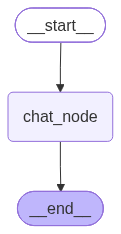

In [44]:
chatbot

In [45]:
initial_state= {
    'messages': [HumanMessage(content='what is the capital of India')]

}


result= chatbot.invoke(initial_state)



In [48]:
print(result['messages'][-1].content)

The capital of India is **New Delhi**.


In [60]:

thread_id= '1'

while True:

    user_message= input('Type here:')

    print('User:', user_message)
    
    user_message_clean= user_message.strip().lower()

    if any(word in user_message_clean for word in ['exit', 'quit', 'bye']):
        break
    config= {'configurable': {'thread_id': thread_id}}
    response= chatbot.invoke({
        'messages': [HumanMessage(content= user_message)]
    }, config = config)
    

    print('AI: ', response['messages'][-1].content)




User: hi 
AI:  Hello again! How can I help you today?
User: Hi there
AI:  Hi there! 👋 How can I assist you today?
User: thank you bye 


In [61]:
chatbot.get_state(config= config)

StateSnapshot(values={'messages': [HumanMessage(content='hi my name is akshat singh', additional_kwargs={}, response_metadata={}, id='847e1500-6fdb-41dd-b80d-5f7305ad10f5'), AIMessage(content='Hello Akshat! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "hi my name is akshat singh". We need to respond. The user hasn\'t asked a question. We can greet them, ask how we can help. Also we should follow the policy. There\'s no disallowed content. So we can respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 80, 'prompt_tokens': 80, 'total_tokens': 160, 'completion_time': 0.082130775, 'completion_tokens_details': {'reasoning_tokens': 57}, 'prompt_time': 0.003901185, 'prompt_tokens_details': None, 'queue_time': 0.378952755, 'total_time': 0.08603196}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_ed70b23331', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run